In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")          # ca notebook-ul sa gaseasca folderul src/
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import evaluare as ev

In [2]:
#verificare
df = ev.incarca_date("../data/processed/cipro_norvegia.tsv")
train_t, test_t = ev.split_temporal(df, 2012)
print(df.shape, len(train_t), len(test_t))
ev.evalueaza(train_t, test_t).round(3)

(3148, 14) 1723 1425


,AUROC,AUPRC_castig
ST,0.877,0.445
HC0,0.500,0.000
HC2,0.500,0.000
HC5,0.502,0.000
HC10,0.526,0.041
HC20,0.665,0.218
HC50,0.857,0.509
HC100,0.897,0.573


In [3]:
#impartirea pe clustere
frac = len(test_t) / len(df)
niveluri_split = ["aleatoriu", 10, 20, 50, 100]
modele_arata = ["ST", "HC20", "HC50", "HC100"]
rez = {}
for nivel in niveluri_split:
    scoruri = {m: [] for m in modele_arata}
    for seed in range(20):
        if nivel == "aleatoriu":
            tr, te = ev.split_aleatoriu(df, len(df) - len(test_t), len(test_t), seed)
        else:
            tr, te = ev.split_pe_clustere(df, nivel, frac, seed)
        if te["y"].nunique() < 2 or tr["y"].nunique() < 2:
            continue
        for m in modele_arata:
            scor = ev.model_linie(tr, te, ev.MODELE[m])
            scoruri[m].append(ev.metrici(te["y"].values, scor)["AUROC"])
    rez[nivel] = {m: np.nanmean(v) for m, v in scoruri.items()}
tab_cl = pd.DataFrame(rez).round(3)
tab_cl.columns = ["aleatoriu" if c == "aleatoriu" else f"HC{c}" for c in tab_cl.columns]
tab_cl

,aleatoriu,HC10,HC20,HC50,HC100
ST,0.893,0.889,0.877,0.760,0.703
HC20,0.765,0.722,0.500,0.500,0.500
HC50,0.895,0.886,0.860,0.500,0.500
HC100,0.913,0.914,0.893,0.732,0.500


In [4]:
#fractia reala de test
for nivel in [10, 20, 50, 100]:
    tr, te = ev.split_pe_clustere(df, nivel, frac, 0)
    print(f"split la HC{nivel}: test = {len(te)} izolate ({len(te)/len(df):.2f}), prevalenta test = {te['y'].mean():.3f}")

split la HC10: test = 1425 izolate (0.45), prevalenta test = 0.095
split la HC20: test = 1425 izolate (0.45), prevalenta test = 0.074
split la HC50: test = 1425 izolate (0.45), prevalenta test = 0.072
split la HC100: test = 1743 izolate (0.55), prevalenta test = 0.079


In [5]:
#controlul cu distanta potrivita
rez_c = [ev.control_distanta(df, seed=s) for s in range(300)]
rez_c = pd.DataFrame([r for r in rez_c if r is not None])
print(len(rez_c), "experimente valide din 300")
print(rez_c[["n_antrenare", "n_control", "prev_temporal", "prev_control"]].mean().round(3))
coloane = ["AUROC_temporal", "AUROC_control", "delta_AUROC", "castig_temporal", "castig_control", "delta_castig"]
rezumat = pd.DataFrame({"medie": rez_c[coloane].mean(),
                        "IC95_jos": rez_c[coloane].quantile(0.025),
                        "IC95_sus": rez_c[coloane].quantile(0.975)}).round(3)
rezumat

300 experimente valide din 300
n_antrenare      1119.000
n_control         399.527
prev_temporal       0.137
prev_control        0.062
dtype: float64


,medie,IC95_jos,IC95_sus
AUROC_temporal,0.843,0.805,0.878
AUROC_control,0.867,0.788,0.940
delta_AUROC,-0.024,-0.104,0.065
castig_temporal,0.480,0.387,0.548
castig_control,0.452,0.206,0.700
delta_castig,0.027,-0.227,0.301


In [6]:
#verificare ca distributiile s-au potrivit
rez1, tr1, nou1, ctrl1 = ev.control_distanta(df, seed=0, returneaza_seturi=True)
pd.DataFrame({"temporal": ev.bin_distanta(ev.distanta_minima(tr1, nou1)).value_counts(normalize=True),
              "control": ev.bin_distanta(ev.distanta_minima(tr1, ctrl1)).value_counts(normalize=True)}).round(3)

,temporal,control
HC50,0.404,0.404
HC100,0.246,0.245
>HC100,0.237,0.238
HC20,0.105,0.105
<=HC10,0.008,0.010


In [7]:
#sensibilitate la dimensiunea antrenarii
for frac_tr in [0.5, 0.65, 0.8]:
    r = pd.DataFrame([x for x in (ev.control_distanta(df, frac_train=frac_tr, seed=s) for s in range(100)) if x is not None])
    print(frac_tr, len(r), round(r["delta_AUROC"].mean(), 3), r["delta_AUROC"].quantile([0.025, 0.975]).round(3).tolist())

0.5 100 -0.039 [-0.113, 0.018]
0.65 100 -0.023 [-0.104, 0.079]
0.8 100 -0.021 [-0.125, 0.105]


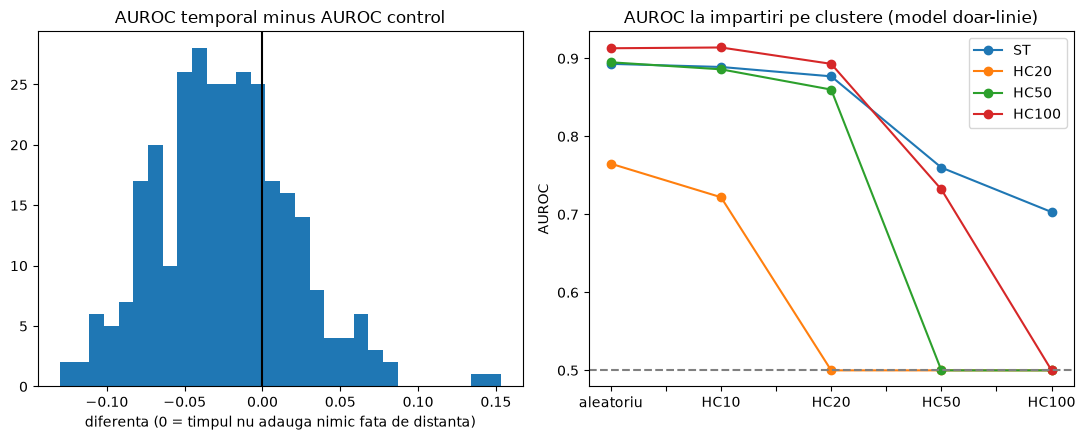

In [8]:
#figura
os.makedirs("../results", exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].hist(rez_c["delta_AUROC"].dropna(), bins=30)
ax[0].axvline(0, color="black")
ax[0].set_title("AUROC temporal minus AUROC control")
ax[0].set_xlabel("diferenta (0 = timpul nu adauga nimic fata de distanta)")
tab_cl.T.plot(marker="o", ax=ax[1])
ax[1].set_title("AUROC la impartiri pe clustere (model doar-linie)")
ax[1].set_ylabel("AUROC")
ax[1].axhline(0.5, color="gray", linestyle="--")
plt.tight_layout()
plt.savefig("../results/control_distanta.png", dpi=150, bbox_inches="tight")

In [9]:
#regresia la nivel de izolat, partea 1
import statsmodels.formula.api as smf
reg = ev.tabel_regresie(df, 2012, "HC50")
pd.crosstab(reg["decalaj"], reg["d_bin"], normalize="index").round(2)

d_bin,<=HC10,>HC100,HC100,HC20,HC50
decalaj,,,,,
1,0.00,0.22,0.26,0.10,0.42
2,0.01,0.17,0.30,0.11,0.42
3,0.01,0.21,0.24,0.10,0.43
4,0.03,0.20,0.25,0.11,0.41
5,0.00,0.22,0.26,0.12,0.40


In [10]:
#regresia, partea 2
grup = reg["cgmlst_hc100"]    # izolatele din acelasi cluster nu sunt independente

def ajusteaza(formula, rezultat):
    d = reg.assign(rezultat=reg[rezultat])
    return smf.ols(f"rezultat ~ {formula}", data=d).fit(cov_type="cluster", cov_kwds={"groups": grup})

linii = []
for rezultat in ["eroare", "rezidual"]:
    for nume, formula in [("doar decalaj", "decalaj"), ("decalaj + distanta", "C(d_bin) + decalaj")]:
        m = ajusteaza(formula, rezultat)
        ic = m.conf_int().loc["decalaj"]
        linii.append({"rezultat": rezultat, "model": nume, "coef_decalaj": m.params["decalaj"],
                      "IC_jos": ic[0], "IC_sus": ic[1], "p": m.pvalues["decalaj"]})
tab_reg = pd.DataFrame(linii).round(4)
tab_reg

,rezultat,model,coef_decalaj,IC_jos,IC_sus,p
0,eroare,doar decalaj,-0.0021,-0.0091,0.0049,0.5592
1,eroare,decalaj + distanta,-0.0022,-0.0091,0.0047,0.5297
2,rezidual,doar decalaj,-0.0013,-0.0096,0.0070,0.7608
3,rezidual,decalaj + distanta,-0.0015,-0.0097,0.0068,0.7262


In [11]:
rezumat.to_csv("../results/control_distanta_rezumat.csv")
tab_cl.to_csv("../results/impartiri_pe_clustere.csv")
tab_reg.to_csv("../results/regresie_izolat.csv", index=False)